# TD Two-factor analysis of variance

Christelle Gonindard & Matthias Grenié


## 1. Objective

**To test the effect of two factors (X1 and X2: qualitative variables) on another variable Y which is quantitative**.

## 2. 2-factor analysis of variance

### 2.1 Data presentation

The purpose of two-factor analysis of variance is to test the effect of 2 factors on a response variable.
response variable. In the case of a complete balanced design, adding 2 factors also implies the presence of an interaction.
the presence of an interaction.

We propose to study the influence on the yield (expressed in %) of a chemical reaction,
of the following two factors:

- T: temperature at two levels: T1 lower level 20 degrees Celsius and T2 upper level 50 degrees Celsius,
- V: stirring speed at two levels: V1 lower level slow speed and V2 upper level fast speed.

We therefore have:
- A factor X1: `temperature` with two levels (p=2)
- A factor X2: `speed` with two levels (q=2)
- A quantitative variable Y: `yield`

The data are contained in the text file `TD10_chemical_reaction.txt` in the folder `data/`


1. Read data 

In [2]:
# Read data file
reaction = read.table("data/TD10_chemical_reaction.txt", header = TRUE)

# Display start of data file contents 
head(reaction)

summary(reaction$yield)

table(reaction$temperature, reaction$speed)

,yield,temperature,speed
,<int>,<chr>,<chr>
1,52,T1,V1
2,53,T1,V1
3,51,T1,V1
4,53,T1,V1
5,54,T1,V1
6,55,T1,V1


   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
  51.00   60.25   66.00   63.67   69.00   72.00 

    
     V1 V2
  T1  6  6
  T2  6  6

### 2.2 Description of the samples

We wish to study the quantitative variable yield and check whether there is an effect of the variables
of the variables temperature and speed on the yield of the chemical reaction. 

A quick way
visualize the data is to plot boxplots representing the yield variable as a function of the
as a function of the different classes of temperature and speed variables.

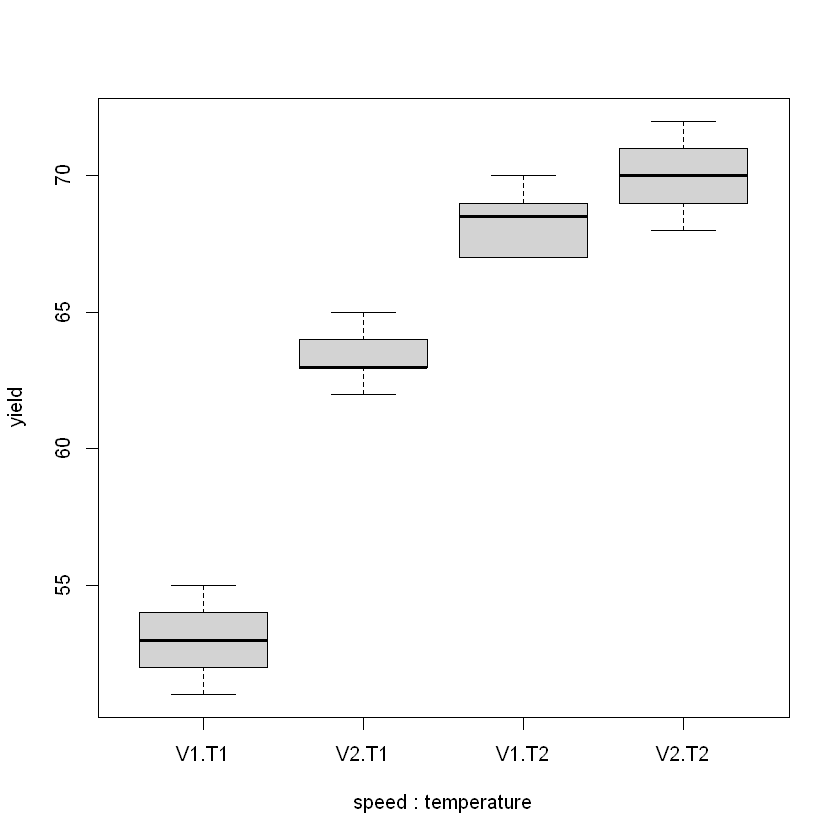

In [3]:
# Plot the boxplot showing efficiency as a function of speed and temperature
boxplot(yield ~ speed + temperature, data = reaction)

**Comment:**  
Given the boxplot it seems that both speed and temperature seem to have an effect on yield. It seems that temperature has overall the strongest effect with higher temperatures showing higher yields.
However, speed also has an effect that is especially important with a low speed.

### 2.3 Two-factor anova hypothesis

The following hypotheses will be tested:




H0 : The average yield is the same whatever the speed

H1 : The average yield differs depending on the speed

H0' : The average yield is the same whatever the temperature

H1' : The average yield differs depending on the temperature

H0" : Speed and temperature jointly do not affect average yield

H1" : Speed and temperature jointly affect average yield



### 2.4 Two-factor anova application conditions

Before applying the test, it is necessary to check the following application conditions:

1. Normality of each sample.
2. Equality of variances between samples.

#### a) Sample normality

We will test the normality of the samples graphically and using the Shapiro-Wilk normality test.
normality test. It is important to note that normality must be tested on all samples. We will first recreate the 4 groups in R:

In [5]:
# Group set-up
v1t1 = reaction$yield[reaction$speed == "V1" & reaction$temperature == "T1"]
v1t1

v2t1 = reaction$yield[reaction$speed == "V2" & reaction$temperature == "T1"]

v1t2 = reaction$yield[reaction$speed == "V1" & reaction$temperature == "T2"]

v2t2 = reaction$yield[reaction$speed == "V2" & reaction$temperature == "T2"]

[1] 52 53 51 53 54 55

We will apply the shapiro test for each of these three groups.

Specify the hypotheses


H0 : The sample follows a normal distribution

H1 : The sample doesn't follow a normal distribution

Perform the Shapiro test

In [6]:
# Shapiro test
shapiro.test(v1t1)
shapiro.test(v2t1)
shapiro.test(v1t2)
shapiro.test(v2t2)



	Shapiro-Wilk normality test

data:  v1t1
W = 0.98176, p-value = 0.96



	Shapiro-Wilk normality test

data:  v2t1
W = 0.91546, p-value = 0.4733



	Shapiro-Wilk normality test

data:  v1t2
W = 0.9067, p-value = 0.415



	Shapiro-Wilk normality test

data:  v2t2
W = 0.98176, p-value = 0.96


**Conclusion**:  
All p >>> alpha = 0.05, so we can't reject H0 for all samples, as such they all follow a normal distribution

Plot graphs fitting data to theoretical quantiles of the normal distribution

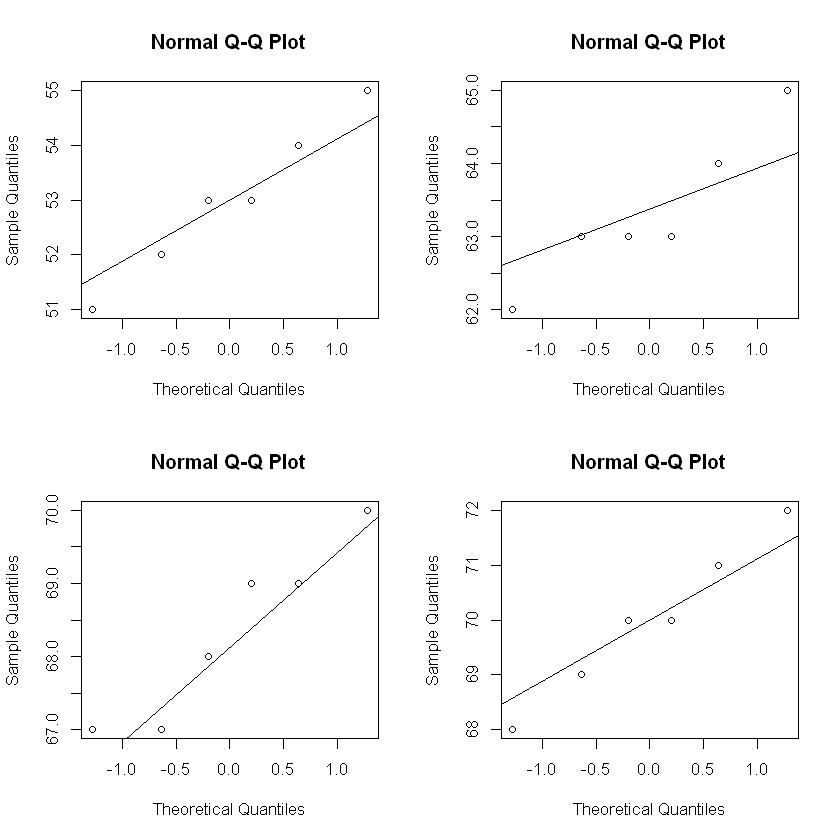

In [7]:
par(mfrow = c(2, 2))
qqnorm(v1t1)
qqline(v1t1)

qqnorm(v2t1)
qqline(v2t1)

qqnorm(v1t2)
qqline(v1t2)

qqnorm(v2t2)
qqline(v2t2)

**Comment:**  
Graphically it seems that all samples follow a normal distribution

#### b) Test for equality of variance of each sample

Let's apply Bartlett's test, as for the one-factor anova, to compare the variances of all samples at the same time.
at the same time. The working hypotheses are :

H0 : The variances of all samples are equal 

H1 : The variance of one sample, at least, is different from the others

Let's perform Bartlett's test on R. 

To apply this test, we need to associate each yield in R with the sample to which it belongs (e.g. T1V1 or T2V1, etc.). 

To do this, we'll use the `paste()` function, which glues two columns together. If the information contained in the temperature and velocity columns are associated, then this new column will represent the sample name for each yield, and we can apply Bartlett's test between yield and sample name as for the one-factor anova.

In [9]:
# Bartlett's test
reaction$group = paste(reaction$speed, reaction$temperature, sep = ".")

bartlett.test(yield ~ group, data = reaction)


	Bartlett test of homogeneity of variances

data:  yield by group
Bartlett's K-squared = 0.59385, df = 3, p-value = 0.8978


**Conclusion:**  
We observe p = 0.90 >>> alpha = 0.05, so we can't reject H0, and thus the variance are equal.

### 2.5 Performing the two-factor ANOVA test

The ANOVA is then easily performed using the `aov()` function.

In [12]:
# Calculate anova
aov_reaction = aov(yield ~ speed*temperature, data = reaction)

# Display anova results
summary(aov_reaction)

                  Df Sum Sq Mean Sq F value   Pr(>F)    
speed              1  216.0   216.0  132.25 2.87e-10 ***
temperature        1  726.0   726.0  444.49 3.94e-15 ***
speed:temperature  1  112.7   112.7   68.98 6.50e-08 ***
Residuals         20   32.7     1.6                     
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

**Conclusion**:  
We observe p <<< alpha = 0.05 for all three variables (speed, temperature, and the interaction between speed and temperature), so we reject H0, H0', and H0'', which means we observe a difference in average yield at different speeds, temperatures, and combined.

### 2.6 Course reminder: Interpretation of the two-factor anova table (see course)

Total yield variability can be broken down into four parts:

- temperature variability on yield
- variability due to speed on yield
- variability due to the interaction of temperature and speed on yield
- variability due to the reaction itself on yield (random variability)

This translates into :

> **Total variability = Temperature variability + Speed variability + Interaction variability + Random variability**

If we return to the anova results table :

In [16]:
summary(aov_reaction)

                  Df Sum Sq Mean Sq F value   Pr(>F)    
speed              1  216.0   216.0  132.25 2.87e-10 ***
temperature        1  726.0   726.0  444.49 3.94e-15 ***
speed:temperature  1  112.7   112.7   68.98 6.50e-08 ***
Residuals         20   32.7     1.6                     
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

The `Sum Sq` column corresponds to yield variability and is broken down into 4 parts: 

Total variability = Temperature variability + Speed variability + Interaction variability + Random variability

So

Total variability = 726 + 216 + 112.7 + 32.7 = 1087.4

the `Mean Sq` column corresponds to the yield variance: 
- variance due to temperature
is 726
- the variance due to speed is 216
- variance due to interaction 112.7 
- random variance 1.6.

To find out whether there is a difference between yields as a function of temperature, speed or interaction
or interaction, which can also be translated as “is there an effect of the factors
temperature, speed and interaction on the yield variable?”, the principle is simple:

the proportion of variation
of variation due to the effect of each factor is compared with the share of variation due to randomness.
random.

All that needs to be done is to test whether the variance of the factors is significantly greater than the residual (random) variance.
residual (random) variance using a Fisher-Snedecor test.


H0 : Temperature variance = Random variance <=> no effect of temperature factor

H1 : Variance temperature > Random variance <=> effect of temperature factor

$$ F=\frac{Variance_{temperature}}{Variance_{random}}=444.49 $$

**Conclusion**: the pvalue of Fisher's test is $3.94 10^{-15}$, i.e. less than 0.05, so we can reject
H0, temperature has an influence on yield.




H0: Speed variance = Random variance <=> no effect of speed factor

H1: Speed variance > Random variance <=> effect of speed factor

$$ F=\frac{Variance_{speed}}{Variance_{random}}=132.25 $$

**Conclusion**: the pvalue of Fisher's test is equal to $2.87 10^{-10}$, i.e. less than 0.05, so we can reject
H0, speed has an influence on yield.




H0 : Variance interaction = Random variance <=> no effect of interaction factor

H1 : Interaction variance > Random variance <=> effect of interaction factor

$$ F=\frac{Variance_{interaction}}{Variance_{random}}=68.98 $$

**Conclusion**: the pvalue of Fisher's test is equal to $6.5 10^{-8}$, i.e. less than 0.05, so we can reject
H0 can be rejected, interaction has an influence on yield.

## 3. Exercise

Three (fixed) operators in a laboratory perform the radioimmunoassay of a substance S, using three (fixed) batches of reagents.
radioimmunoassay of a substance S, each operator performing four measurements on the same control
control sample, four measurements for each of the three batches.

The results, expressed in IU/mL, are contained in the file
`TD10_dosing.txt` in the `data/` folder.

Answer the following questions:
1. Does the operator have any influence on the radioimmunoassay?
2. Does the batch influence the radioimmunoassay?
3. Does the interaction between the batch and the operator have an influence?



,dosing,operator,unit
,<dbl>,<chr>,<chr>
1,8.7,operator1,unit1
2,9.1,operator1,unit1
3,8.6,operator1,unit1
4,8.4,operator1,unit1
5,9.1,operator1,unit2
6,9.4,operator1,unit2


   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
  8.000   8.500   8.800   8.758   8.925   9.400 

           
            unit1 unit2 unit3
  operator1     4     4     4
  operator2     4     4     4
  operator3     4     4     4

$unit1.operator1

	Shapiro-Wilk normality test

data:  df$dosing
W = 0.95278, p-value = 0.7335


$unit1.operator2

	Shapiro-Wilk normality test

data:  df$dosing
W = 0.92708, p-value = 0.5774


$unit1.operator3

	Shapiro-Wilk normality test

data:  df$dosing
W = 0.99291, p-value = 0.9719


$unit2.operator1

	Shapiro-Wilk normality test

data:  df$dosing
W = 0.94971, p-value = 0.7143


$unit2.operator2

	Shapiro-Wilk normality test

data:  df$dosing
W = 0.94466, p-value = 0.683


$unit2.operator3

	Shapiro-Wilk normality test

data:  df$dosing
W = 0.82745, p-value = 0.1612


$unit3.operator1

	Shapiro-Wilk normality test

data:  df$dosing
W = 0.86038, p-value = 0.2616


$unit3.operator2

	Shapiro-Wilk normality test

data:  df$dosing
W = 0.99291, p-value = 0.9719


$unit3.operator3

	Shapiro-Wilk normality test

data:  df$dosing
W = 0.99291, p-value = 0.9719




	Bartlett test of homogeneity of variances

data:  dosing by group
Bartlett's K-squared = 14.671, df = 8, p-value = 0.06587


              Df Sum Sq Mean Sq F value  Pr(>F)   
unit           2 0.3217  0.1608   2.443 0.10588   
operator       2 1.1817  0.5908   8.975 0.00103 **
unit:operator  4 0.3267  0.0817   1.241 0.31741   
Residuals     27 1.7775  0.0658                   
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

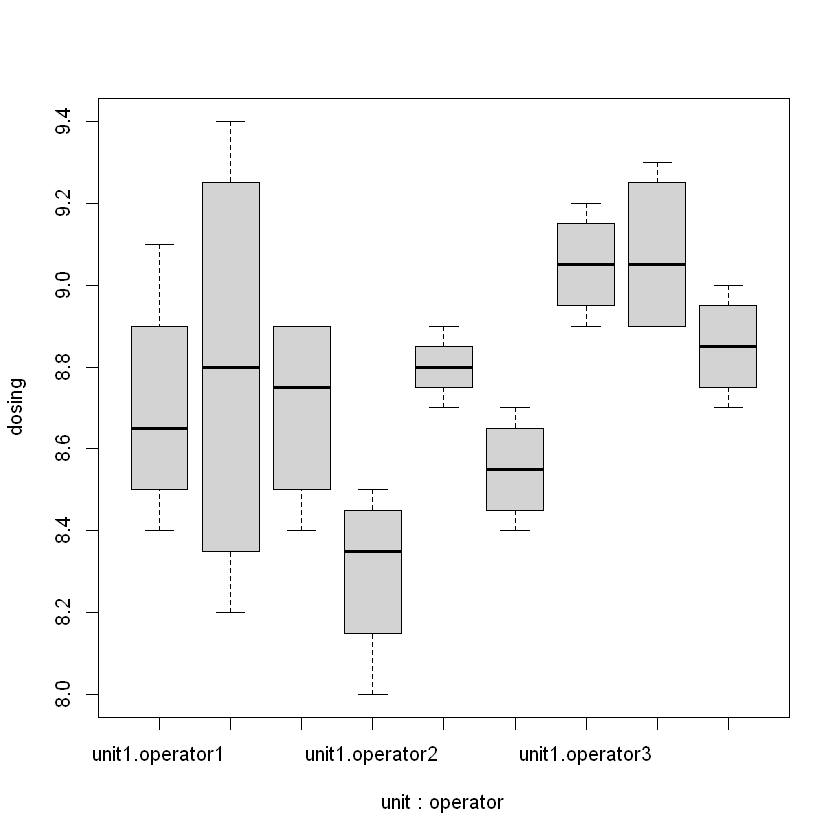

In [27]:
dosing = read.table("data/TD10_dosing.txt", header = TRUE)

head(dosing)
summary(dosing$dosing)
table(dosing$operator, dosing$unit)

boxplot(dosing ~ unit + operator, data = dosing)
# => given the boxplot, it seems the operator has an effect but no so much the unit
# let's test this with an two factor ANOVA
# Hypotheses ----
# Effect of units
# H0: No difference of dosing between units
# H1: At least one difference of dosing between units
# Effect of operators
# H0': No difference of dosing between operators
# H1': At least one difference of dosing betwee operators
# Joit effect of units and operators
# H0'': No joint effect of units and operators on average dosing
# H1'': Joint effect of units and operators on average dosing

# Let's check the assumptions

# Make groups
dosing$group = paste(dosing$unit, dosing$operator, sep = ".")

# Normality of samples
all_groups = split(dosing, dosing$group)

# Perform a Shapiro test
lapply(all_groups, \(df) shapiro.test(df$dosing))
# => all p >>> alpha = 0.05, so we can't reject H0, and all groups show a normal distribution of dosing

# Equality of variance = Bartlett's test
# H0: all variance are equal
# H1: at least one is different from the others
bartlett.test(dosing ~ group, data = dosing)
# => p = 0.066 > alpha = 0.05, so we can't reject H0, and the variances of all groups are the same (but we can discuss the proximity to the threshold)

# Perform the ANOVA
aov_dosing = aov(dosing ~ unit*operator, data = dosing)
summary(aov_dosing)
# => We only observe p < alpha = 0.05, for the operator variable, so we reject that H0, as such the only variable influencing the radioimmunoassay is the operator.